# 01 · Exploración de los datos de LaLiga

**Objetivo del proyecto.** Construir un modelo que, antes de un partido de LaLiga, estime la probabilidad de que gane el local, empate o gane el visitante, y comprobar si es capaz de acercarse a lo que "saben" las casas de apuestas.

**Objetivo de este cuaderno.** Conocer los datos antes de modelar nada. Responderemos a cuatro preguntas:

1. ¿Qué datos tenemos y están completos?
2. ¿Cuánto vale jugar en casa?
3. ¿Se parecen los goles de un partido a una **distribución de Poisson**? (es la hipótesis sobre la que se apoyará el modelo)
4. ¿Qué probabilidades esconden las **cuotas** de las casas de apuestas y con qué precisión predicen?

Al final fijaremos **la vara de medir**: un número que nuestro modelo tendrá que batir.

*Datos: resultados y cuotas de LaLiga (Primera División), temporadas 2005/06 a 2026/27, de [football-data.co.uk](https://www.football-data.co.uk). Se descargan con `scripts/descargar_datos.py`.*

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import futbol as fb

fb.estilo()
pd.set_option("display.width", 140)
%matplotlib inline

## 1. Los datos

Cada **fila es un partido**. La función `cargar_laliga()` lee los CSV de todas las temporadas, deja solo las columnas que nos interesan, les da nombres claros y convierte las fechas (las primeras temporadas usan años de dos cifras, como `27/08/05`).

In [2]:
df = fb.cargar_laliga()
print(f"{fb.miles(len(df))} partidos, {df['temporada'].nunique()} temporadas, {df['local'].nunique()} equipos distintos")
print(f"Del {df['fecha'].min().date()} al {df['fecha'].max().date()}")
df[["fecha", "temporada", "local", "visitante", "goles_local", "goles_visitante", "resultado",
    "b365_local", "b365_empate", "b365_visitante"]].head()

8.058 partidos, 22 temporadas, 41 equipos distintos
Del 2005-08-27 al 2026-10-12


,fecha,temporada,local,visitante,goles_local,goles_visitante,resultado,b365_local,b365_empate,b365_visitante
0,2005-08-27,2005-06,Alaves,Barcelona,0,0,D,7.00,3.75,1.50
1,2005-08-27,2005-06,Ath Bilbao,Sociedad,3,0,H,2.00,3.25,3.25
2,2005-08-27,2005-06,Valencia,Betis,1,0,H,2.00,3.25,3.25
3,2005-08-28,2005-06,Ath Madrid,Zaragoza,0,0,D,1.72,3.40,4.00
4,2005-08-28,2005-06,Cadiz,Real Madrid,1,2,A,7.50,4.00,1.44


* `resultado`: **H** (*home*) gana el local, **D** (*draw*) empate, **A** (*away*) gana el visitante.
* Las **cuotas** son decimales: una cuota de 2,50 significa que apostando 1 € recibes 2,50 € si aciertas. Cuanto más baja la cuota, más probable considera la casa ese resultado.
* También hay tiros, tiros a puerta, córners, faltas y tarjetas de cada equipo.

### ¿Están completas las temporadas?

Una temporada de LaLiga tiene 380 partidos (20 equipos × 19 rivales × 2 vueltas).

In [3]:
por_temporada = df.groupby("temporada").agg(partidos=("local", "size"), completa=("temporada_completa", "first"))
print(por_temporada[~por_temporada["completa"]])
print(f"\nTemporadas completas: {por_temporada['completa'].sum()} de {len(por_temporada)}")

           partidos  completa
temporada                    
2026-27          78     False

Temporadas completas: 21 de 22


La temporada actual (2026/27) está en curso. **La mantenemos en los datos, pero la dejamos fuera de los análisis por temporada**: con solo unas jornadas jugadas, un porcentaje como "victorias del local" depende de qué equipos han jugado ya y dónde, y engaña. Más adelante nos servirá para otra cosa mejor: son partidos que el modelo nunca habrá visto, una prueba real "hacia el futuro".

In [4]:
completas = df[df["temporada_completa"]]
print(f"{fb.miles(len(completas))} partidos en temporadas completas")

7.980 partidos en temporadas completas


## 2. ¿Cuánto vale jugar en casa?

In [5]:
resumen = completas["resultado"].value_counts(normalize=True).reindex(["H", "D", "A"]) * 100
print("Resultados (temporadas completas):")
print(f"  Gana el local:     {resumen['H']:.1f} %")
print(f"  Empate:            {resumen['D']:.1f} %")
print(f"  Gana el visitante: {resumen['A']:.1f} %")
print(f"\nGoles por partido:  local {completas['goles_local'].mean():.2f}   visitante {completas['goles_visitante'].mean():.2f}")

Resultados (temporadas completas):
  Gana el local:     46.7 %
  Empate:            24.9 %
  Gana el visitante: 28.3 %

Goles por partido:  local 1.53   visitante 1.13


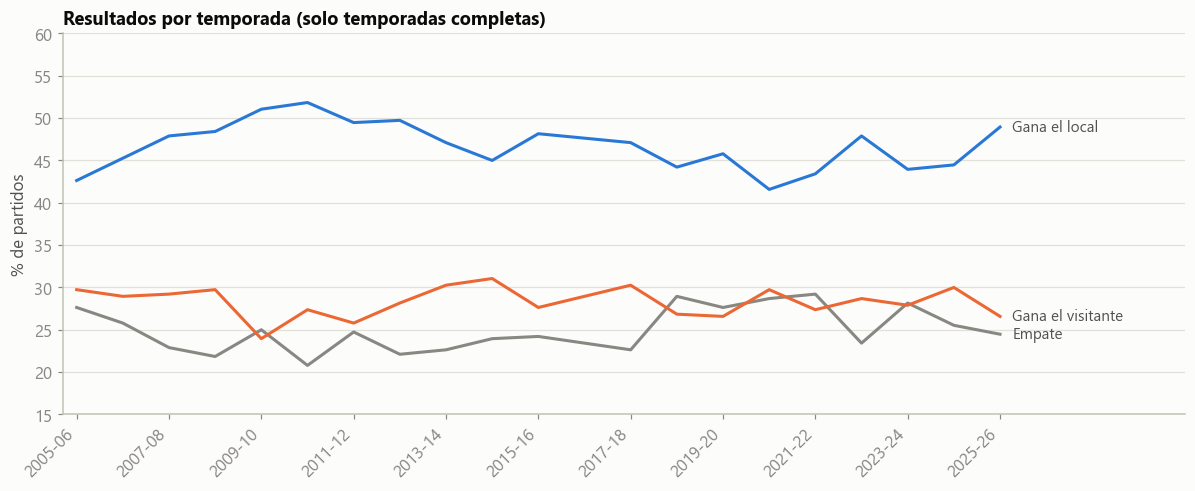

resultado     H     D     A
temporada                  
2020-21    41.6  28.7  29.7
2005-06    42.6  27.6  29.7
2009-10    51.1  25.0  23.9
2010-11    51.8  20.8  27.4


In [6]:
por_temp = completas.groupby("temporada")["resultado"].value_counts(normalize=True).unstack()[["H", "D", "A"]] * 100
x = np.arange(len(por_temp))

fig, ax = plt.subplots(figsize=(11, 4.6))
for col, color, nombre in [("H", fb.COLOR_LOCAL, "Gana el local"), ("D", fb.COLOR_EMPATE, "Empate"),
                           ("A", fb.COLOR_VISITANTE, "Gana el visitante")]:
    ax.plot(x, por_temp[col], color=color, lw=2)
    ax.annotate(nombre, (x[-1], por_temp[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                color=fb.TINTA_SECUNDARIA, va="center", fontsize=10)
ax.set_xticks(x[::2])
ax.set_xticklabels(por_temp.index[::2], rotation=45, ha="right")
ax.set_xlim(x[0] - 0.3, x[-1] + 4)
ax.set_ylim(15, 60)
ax.set_ylabel("% de partidos")
ax.set_title("Resultados por temporada (solo temporadas completas)")
plt.tight_layout()
plt.show()

print(por_temp.round(1).sort_values("H").iloc[[0, 1, -2, -1]])

**Jugar en casa vale, y mucho.** El local gana el 46,7 % de los partidos y el visitante el 28,3 %. Además el local marca de media 1,53 goles frente a 1,13 del visitante: unos 0,4 goles por partido de ventaja.

Por temporadas hay oscilaciones, desde el 41,6 % de victorias locales (2020/21, con estadios casi vacíos por la pandemia) hasta el 51,8 % (2010/11). Pero ojo: con solo 380 partidos por temporada, ese porcentaje tiene un margen de error de unos ±2,5 puntos, así que parte de la oscilación es azar. De hecho, 2005/06 (42,6 %) fue casi igual de baja que 2020/21, de modo que **no podemos atribuir a la pandemia** el descenso de una sola temporada. Lo que sí es claro: en todas las temporadas el local gana más que el visitante, y el modelo tendrá que incluir esta ventaja.

## 3. ¿Siguen los goles una distribución de Poisson?

**La idea.** Un partido de fútbol tiene pocos goles, que ocurren "de vez en cuando" y de forma casi independiente. Ese es el tipo de fenómeno que describe la **distribución de Poisson**: si de media se marcan λ goles, la probabilidad de ver exactamente *k* es

$$P(k) = \frac{\lambda^k e^{-\lambda}}{k!}.$$

Es la hipótesis de partida de casi todos los modelos de goles. La comprobamos comparando la frecuencia real de 0, 1, 2… goles con la que predice una Poisson con la misma media. Una propiedad útil: en una Poisson, **varianza = media**.

Goles del local    : media = 1.533, varianza = 1.709, varianza/media = 1.115
   chi-cuadrado = 50.8 con 5 grados de libertad, p = 0.000
Goles del visitante: media = 1.132, varianza = 1.253, varianza/media = 1.107
   chi-cuadrado = 50.7 con 5 grados de libertad, p = 0.000


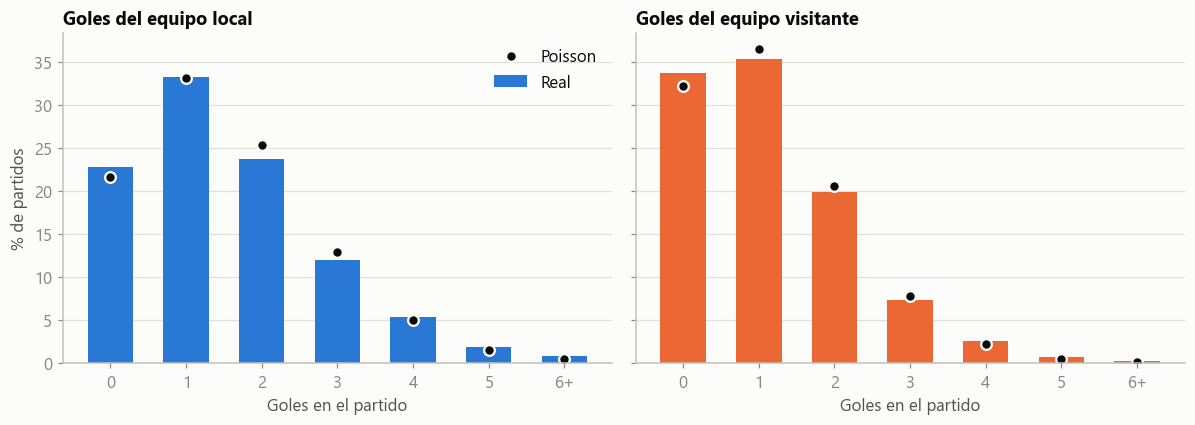

In [7]:
def comparar_poisson(goles, nombre):
    lam = goles.mean()
    k = np.arange(0, 6)
    observados = np.array([(goles == i).mean() for i in k] + [(goles >= 6).mean()])
    esperados = np.append(stats.poisson.pmf(k, lam), stats.poisson.sf(5, lam))
    n = len(goles)
    chi2 = (n * (observados - esperados) ** 2 / esperados).sum()
    gl = len(esperados) - 1 - 1            # categorías - 1 - parámetros estimados (λ)
    print(f"{nombre}: media = {lam:.3f}, varianza = {goles.var():.3f}, varianza/media = {goles.var() / lam:.3f}")
    print(f"   chi-cuadrado = {chi2:.1f} con {gl} grados de libertad, p = {stats.chi2.sf(chi2, gl):.3f}")
    return observados, esperados

obs_l, esp_l = comparar_poisson(completas["goles_local"], "Goles del local    ")
obs_v, esp_v = comparar_poisson(completas["goles_visitante"], "Goles del visitante")

etiquetas = ["0", "1", "2", "3", "4", "5", "6+"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, obs, esp, color, titulo in [(axes[0], obs_l, esp_l, fb.COLOR_LOCAL, "Goles del equipo local"),
                                    (axes[1], obs_v, esp_v, fb.COLOR_VISITANTE, "Goles del equipo visitante")]:
    ax.bar(etiquetas, obs * 100, color=color, width=0.6, label="Real")
    ax.plot(etiquetas, esp * 100, "o", color=fb.TINTA, markersize=7, markeredgecolor=fb.SUPERFICIE,
            markeredgewidth=1.5, label="Poisson")
    ax.set_title(titulo)
    ax.set_xlabel("Goles en el partido")
    pass
axes[0].set_ylabel("% de partidos")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

**La Poisson encaja a grandes rasgos, pero no del todo.** Las barras (lo real) y los puntos (lo que predice la Poisson) se parecen mucho, pero la varianza de los goles es algo mayor que su media (1,71 frente a 1,53 en el local y 1,25 frente a 1,13 en el visitante; cociente ≈ 1,11, cuando en una Poisson sería 1). En el gráfico se nota en que hay **más partidos de lo esperado con 0 goles y con 4 o más, y menos con 2**. El test chi-cuadrado rechaza la Poisson exacta (p ≈ 0), algo normal con casi 8 000 partidos, donde se detectan diferencias pequeñas.

Hay una explicación natural: aquí hemos mezclado todos los equipos, y no todos marcan igual (un equipo de arriba marca más que uno recién ascendido). Al mezclar muchas Poisson con ritmos distintos sale una distribución con más varianza que la media. Esto apunta a la solución: **dar a cada equipo su propio ritmo de goles** (ataque y defensa), que es justo lo que hará nuestro modelo; comprobaremos en el siguiente cuaderno si así la hipótesis de Poisson funciona mejor partido a partido.

## 4. De cuotas a probabilidades

Una casa de apuestas ofrece, por ejemplo, 2,00 por un resultado. Eso equivale a una probabilidad de 1 / 2,00 = 50 %. Pero si calculas `1/cuota` para los tres resultados de un partido, **la suma supera 100 %**: el exceso es el **margen** (la comisión) de la casa. Para obtener probabilidades que sumen 1 se reparte ese margen de forma proporcional. Es lo que hace `probabilidades_implicitas()`.

Un ejemplo con un partido real (Athletic - Getafe, 15/08/2024, cuotas de Bet365):

In [8]:
ejemplo = df[(df["fecha"] == "2024-08-15") & (df["local"] == "Ath Bilbao")].iloc[0]
cuotas = np.array([ejemplo["b365_local"], ejemplo["b365_empate"], ejemplo["b365_visitante"]])
probs, margen = fb.probabilidades_implicitas(*cuotas.reshape(3, 1))

print(f"{ejemplo['local']} - {ejemplo['visitante']}  (resultado: {ejemplo['goles_local']}-{ejemplo['goles_visitante']})\n")
print(f"{'':12}{'cuota':>8}{'1/cuota':>10}{'prob. ajustada':>16}")
for nombre, c, p in zip(["Local", "Empate", "Visitante"], cuotas, probs[0]):
    print(f"{nombre:12}{c:8.2f}{1/c*100:9.1f}%{p*100:15.1f}%")
print(f"\nSuma de 1/cuota = {(1/cuotas).sum()*100:.1f} %  ->  margen de la casa = {margen[0]*100:.1f} %")

Ath Bilbao - Getafe  (resultado: 1-1)

               cuota   1/cuota  prob. ajustada
Local           1.48     67.6%           64.3%
Empate          4.00     25.0%           23.8%
Visitante       8.00     12.5%           11.9%

Suma de 1/cuota = 105.1 %  ->  margen de la casa = 5.1 %


### ¿Cuánto se quedan las casas?

Comparamos tres tipos de cuota. Las de **cierre** (justo antes de empezar el partido) incorporan toda la información que ha ido llegando (alineaciones, lesiones, dinero apostado) y son las más precisas. **Pinnacle** es una casa conocida por trabajar con márgenes muy bajos y aceptar a los apostadores profesionales, por lo que se usa como referencia de "precio justo".

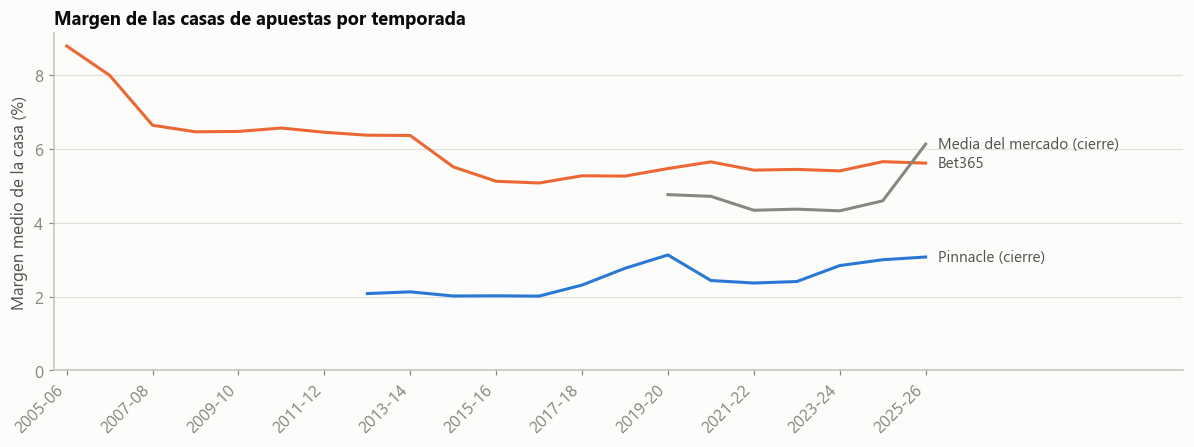

           Bet365  Pinnacle (cierre)  Media del mercado (cierre)
temporada                                                       
2005-06      8.79                NaN                         NaN
2012-13      6.37               2.08                         NaN
2025-26      5.61               3.07                        6.13


In [9]:
def margen_por_temporada(prefijo):
    cols = [f"{prefijo}_local", f"{prefijo}_empate", f"{prefijo}_visitante"]
    d = completas.dropna(subset=cols)
    _, m = fb.probabilidades_implicitas(d[cols[0]], d[cols[1]], d[cols[2]])
    return pd.Series(m * 100, index=d.index).groupby(d["temporada"]).mean()

margenes = pd.DataFrame({"Bet365": margen_por_temporada("b365"),
                         "Pinnacle (cierre)": margen_por_temporada("pinnacle_cierre"),
                         "Media del mercado (cierre)": margen_por_temporada("media_cierre")})

fig, ax = plt.subplots(figsize=(11, 4.2))
colores = {"Bet365": fb.COLOR_VISITANTE, "Pinnacle (cierre)": fb.COLOR_LOCAL, "Media del mercado (cierre)": fb.COLOR_EMPATE}
pos = {t: i for i, t in enumerate(sorted(completas["temporada"].unique()))}
for col in margenes:
    s = margenes[col].dropna()
    xs = [pos[t] for t in s.index]
    ax.plot(xs, s.values, color=colores[col], lw=2)
    ax.annotate(col, (xs[-1], s.values[-1]), xytext=(8, 0), textcoords="offset points", va="center",
                color=fb.TINTA_SECUNDARIA, fontsize=10)
ax.set_xticks(list(pos.values())[::2])
ax.set_xticklabels(list(pos.keys())[::2], rotation=45, ha="right")
ax.set_xlim(-0.3, len(pos) + 5)
ax.set_ylim(0, None)
ax.set_ylabel("Margen medio de la casa (%)")
ax.set_title("Margen de las casas de apuestas por temporada")
plt.tight_layout()
plt.show()

print(margenes.round(2).iloc[[0, 7, -1]])

**Las casas se quedan una comisión, y no todas la misma.** El margen medio de Bet365 bajó del 8,8 % en 2005/06 al 6,4 % en 2012/13 y está en torno al 5,6 % en 2025/26. Pinnacle trabaja con márgenes mucho menores (2,1 % en 2012/13; 3,1 % en 2025/26, y en esta última solo con la mitad de los partidos con dato). Por eso sus cuotas de cierre son la mejor aproximación al "precio justo".

## 5. ¿Aciertan las probabilidades de las casas?

Una forma de comprobar si unas probabilidades son **buenas** se llama **calibración**: de todos los resultados a los que la casa dio, por ejemplo, un 30 % de probabilidad, ¿ocurrieron realmente el 30 % de las veces? Si es así, las probabilidades son honestas.

Se agrupan las predicciones en tramos de probabilidad y se compara la probabilidad media del tramo con la frecuencia real. Usamos las cuotas de cierre de Pinnacle (disponibles desde 2012/13), con los tres resultados de cada partido como una predicción independiente.

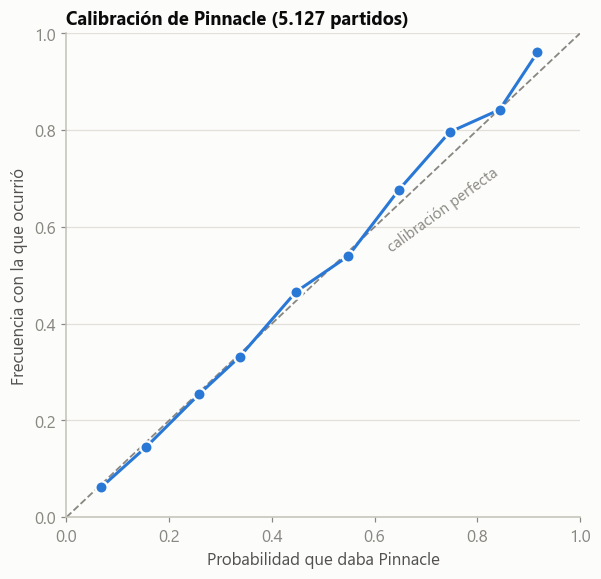

       prob_media  frecuencia_real     n
tramo                                   
0           0.068            0.062   807
1           0.155            0.145  2278
2           0.259            0.255  5221
3           0.337            0.332  2873
4           0.447            0.466  1597
5           0.549            0.540  1121
6           0.647            0.677   733
7           0.746            0.796   446
8           0.844            0.843   254
9           0.917            0.961    51


In [10]:
cols_ps = ["pinnacle_cierre_local", "pinnacle_cierre_empate", "pinnacle_cierre_visitante"]
con_ps = df.dropna(subset=cols_ps).reset_index(drop=True)
p_ps, _ = fb.probabilidades_implicitas(*(con_ps[c] for c in cols_ps))
y = con_ps["resultado"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
real = np.zeros_like(p_ps)
real[np.arange(len(y)), y] = 1                                  # 1 si ese resultado ocurrió

prob_plana, real_plana = p_ps.ravel(), real.ravel()
tramos = np.arange(0.0, 1.0001, 0.1)
cubo = np.clip(np.digitize(prob_plana, tramos) - 1, 0, len(tramos) - 2)
calib = pd.DataFrame({"prob": prob_plana, "real": real_plana, "tramo": cubo}).groupby("tramo").agg(
    prob_media=("prob", "mean"), frecuencia_real=("real", "mean"), n=("real", "size"))

fig, ax = plt.subplots(figsize=(5.6, 5.4))
ax.plot([0, 1], [0, 1], color=fb.TINTA_SUAVE, lw=1.2, ls="--")
ax.plot(calib["prob_media"], calib["frecuencia_real"], "o-", color=fb.COLOR_LOCAL, markersize=8,
        markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
ax.annotate("calibración perfecta", (0.62, 0.55), color=fb.TINTA_SUAVE, fontsize=10, rotation=36)
ax.set_xlabel("Probabilidad que daba Pinnacle")
ax.set_ylabel("Frecuencia con la que ocurrió")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"Calibración de Pinnacle ({fb.miles(len(con_ps))} partidos)")
plt.tight_layout()
plt.show()
print(calib.round(3))

**Las probabilidades de Pinnacle están muy bien calibradas:** los puntos siguen casi exactamente la diagonal. Cuando daba de media un 25,9 % ocurrió el 25,5 %, y cuando daba un 54,9 %, el 54,0 %.

Hay una desviación pequeña en los favoritos: con probabilidades de 65 %, 75 % y 92 % ocurrió el 68 %, 80 % y 96 %. Es decir, los favoritos ganan algo más de lo que el precio sugiere (un sesgo que se conoce en apuestas como *favorito-longshot*). Los tramos altos tienen pocos partidos (solo 51 en el último), así que no hay que sacar conclusiones fuertes de ellos.

## 6. La vara de medir

Para comparar modelos necesitamos **un número**. Usaremos la **pérdida logarítmica** (*log loss*): para cada partido se mira la probabilidad que el modelo dio al resultado que **finalmente ocurrió**, y se promedia el $-\ln$ de esas probabilidades.

* Si el modelo daba 100 % al resultado correcto, la pérdida es 0 (la mejor posible).
* Dar probabilidades bajas a lo que ocurre se castiga mucho: por eso premia a los modelos **honestos**, que no se pasan de seguros.
* Repartir 1/3 a cada resultado da $\ln 3 = 1{,}099$. Todo modelo útil debe quedar por debajo.

Comparamos cuatro "predictores" sobre **los mismos partidos** (los que tienen cuotas de Pinnacle):
1. **Equiprobable**: 1/3, 1/3, 1/3.
2. **Frecuencias históricas**: siempre la misma proporción de victorias locales, empates y visitantes, calculada solo con temporadas anteriores a 2012/13, para no usar información del futuro.
3. **Bet365** (cuotas de antes del partido).
4. **Pinnacle al cierre**.

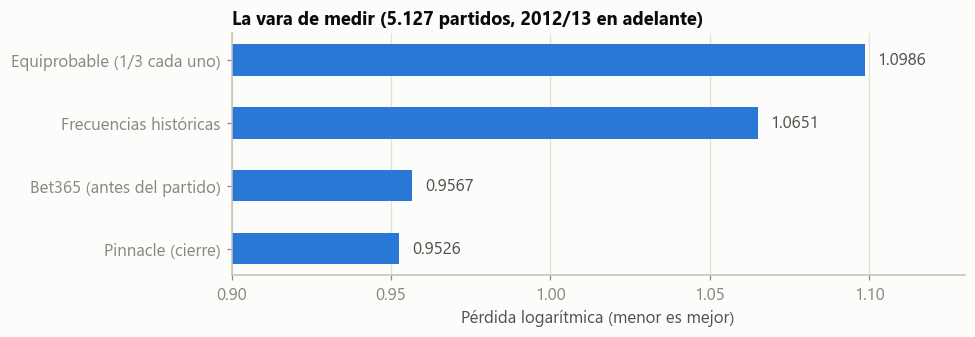

Equiprobable (1/3 cada uno)    1.0986
Frecuencias históricas         1.0651
Bet365 (antes del partido)     0.9567
Pinnacle (cierre)              0.9526
dtype: float64

Frecuencias históricas usadas (local, empate, visitante): [0.481 0.241 0.278]


In [11]:
def log_loss(probs, y):
    return -np.log(probs[np.arange(len(y)), y]).mean()

# Frecuencias históricas: solo con temporadas anteriores a las evaluadas
antes = df[(df["anio_inicio"] < 2012) & df["temporada_completa"]]
freq_hist = antes["resultado"].value_counts(normalize=True).reindex(["H", "D", "A"]).to_numpy()

cols_b365 = ["b365_local", "b365_empate", "b365_visitante"]
p_b365, _ = fb.probabilidades_implicitas(*(con_ps[c] for c in cols_b365))

vara = pd.Series({
    "Equiprobable (1/3 cada uno)": log_loss(np.full_like(p_ps, 1 / 3), y),
    "Frecuencias históricas": log_loss(np.tile(freq_hist, (len(y), 1)), y),
    "Bet365 (antes del partido)": log_loss(p_b365, y),
    "Pinnacle (cierre)": log_loss(p_ps, y),
})

fig, ax = plt.subplots(figsize=(9, 3.2))
barras = ax.barh(vara.index[::-1], vara.values[::-1], color=fb.COLOR_LOCAL, height=0.5)
for rect, v in zip(barras, vara.values[::-1]):
    ax.text(v + 0.004, rect.get_y() + rect.get_height() / 2, f"{v:.4f}", va="center", color=fb.TINTA_SECUNDARIA)
ax.set_xlim(0.9, 1.13)
ax.set_xlabel("Pérdida logarítmica (menor es mejor)")
ax.set_title(f"La vara de medir ({fb.miles(len(y))} partidos, 2012/13 en adelante)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
plt.tight_layout()
plt.show()
print(vara.round(4))
print(f"\nFrecuencias históricas usadas (local, empate, visitante): {np.round(freq_hist, 3)}")

**Lo que mide la vara:**

| Predictor | Pérdida logarítmica |
|---|---|
| Equiprobable | 1,0986 |
| Frecuencias históricas | 1,0651 |
| Bet365 (antes del partido) | 0,9567 |
| **Pinnacle (cierre)** | **0,9526** |

* Saber solo que "el local gana más" mejora muy poco (−0,034 respecto al reparto uniforme).
* Las cuotas son un salto enorme: Pinnacle está 0,112 por debajo de las frecuencias históricas. Y Bet365, que publica sus cuotas antes que el cierre, queda a solo 0,004 de Pinnacle.

**Qué es realista esperar.** Nuestro modelo usará únicamente resultados pasados, sin alineaciones, lesiones ni dinero apostado, información que el mercado sí tiene. Así que **no esperamos batir a Pinnacle**; lo honesto es medir *cuánto del hueco* entre las frecuencias históricas (1,065) y Pinnacle (0,953) conseguimos cerrar:

$$\text{hueco cerrado} = \frac{1{,}0651 - \text{pérdida del modelo}}{1{,}0651 - 0{,}9526}.$$

## 7. Qué hemos aprendido y qué sigue

* **Datos:** 21 temporadas completas (7 980 partidos) más la actual en curso, sin duplicados ni nombres de equipo incoherentes. Hay cuotas de Bet365 en todos los partidos y de Pinnacle desde 2012/13.
* **Jugar en casa vale:** 46,7 % de victorias locales frente a 28,3 % del visitante, unos 0,4 goles por partido.
* **Los goles se parecen a una Poisson, con algo más de varianza**, lo que se explica por mezclar equipos de distinta calidad. Hay que modelar el ataque y la defensa de cada equipo.
* **Las cuotas de cierre de Pinnacle están muy bien calibradas** y fijan la vara de medir: pérdida logarítmica 0,9526, frente a 1,0651 de las frecuencias históricas.

### Siguiente cuaderno: el modelo

1. Un modelo de Poisson donde los goles esperados de cada equipo dependen de su **ataque**, de la **defensa del rival** y de la **ventaja de jugar en casa**.
2. Entrenarlo siempre con el pasado y evaluarlo en partidos posteriores (validación temporal), sin mirar nunca el futuro.
3. Medir cuánto del hueco entre las frecuencias históricas y Pinnacle consigue cerrar.